# 10 · Macro factors from large public panels

The three-series DRA model overfits (notebook 03), and only the policy rate
carries information about future yields, in USD only (notebooks 03–04). The
factor-model answer is to summarise a large macro panel in one or two
factors (Moench 2008; Coroneo, Giannone & Modugno 2016) and let those enter
the state like the policy rate (README §8 step 7b, item 7).

**Fixed before the run** (commit `4f0ec02`; `yck.model.macro_factors`):

- **Panels.**
  - USD: FRED-MD, 126 series, with every monthly vintage since 1999-08, so
    the USD factors are fully real-time.
  - EUR: EA-MD-QD, the 47 monthly series.
  - GBP: UK-MD, 111 series.

  Interest rates and spreads are excluded, so the factors carry macro
  information rather than the curve itself.
- **Factors** (McCracken & Ng 2016):
  - transformation codes; outliers set to missing;
  - EM principal components on the estimation window;
  - unit variance;
  - sign fixed by industrial production (factor 1) and consumer prices
    (factor 2).
- **Real time.** Factors are re-extracted at every origin from the panel
  known then: the FRED-MD vintage of that month (USD), or the latest file
  cut at each series' publication delay (EUR, GBP; revisions ignored).
- **Models.** Yields + factor 1; yields + factors 1–2; yields + policy
  rate + factors 1–2. Each is run plain and with AR(1) errors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from yck.eval.backtest import dns_kalman_forecasts, dns_two_step_forecasts, random_walk_forecasts, forward_forecasts
from yck.eval.grid import (STANDARD_GRID, BACKTEST_DEFAULTS, accuracy_grid, anchor_grid, shadow_grid, rwprior_grid,
                           svensson_grid, SVENSSON_LAM2, factor_grid, plan_runs,
                           combination_forecasts, ensure_results, tag_of, _grid_for)
from yck.eval.stats import dm_table, mcs_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, CONFIG, DATA = ROOT / "data/results", ROOT / "config/data_sources.yaml", ROOT / "data"
CCYS = ["USD", "EUR", "GBP"]
H = (1, 6, 12)
SHOW = {"USD": ["3m", "12m", "24m", "60m", "120m"], "EUR": ["3m", "12m", "24m", "60m", "120m"],
        "GBP": ["6m", "12m", "24m", "60m", "120m"]}
FIRST_ORIGIN = {c: BACKTEST_DEFAULTS[c][1] for c in CCYS}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
CAP = [{"selector": "caption", "props": "font-weight: bold; text-align: left"}]

GRIDS = (STANDARD_GRID, accuracy_grid, anchor_grid, shadow_grid, rwprior_grid, svensson_grid, factor_grid)
for g in GRIDS:  # one grid run if anything is missing
    ensure_results(CCYS, DATA, CONFIG, grid=g)

def name_of(row):
    m, lam, tau, ep, err, anc, sr, rw, l2 = tuple(row) + (None,) * (9 - len(row))
    LBL = {("policy_rate",): "policy rate", ("factor1",): "1 factor", ("factor1", "factor2"): "2 factors",
           ("policy_rate", "factor1", "factor2"): "policy rate + 2 factors"}
    base = "shadow" if sr else (LBL.get(m, "full macro") if m else "yields")
    base += "" if lam == "fixed" else ", λ est."
    base += f", shrink {tau:g}" if tau is not None else ""
    base += f", RW prior {rw:g}" if rw is not None else ""
    base += f", Svensson {'short' if l2 > 0.1 else 'long'}" if l2 is not None else ""
    base += f", endpoint {ep}" if ep else ""
    base += " + AR(1)" if err == "ar1" else " + AR(1) with mean" if err == "ar1c" else ""
    return base + (", anchored" if anc else "") + (f" ({sr})" if sr else "")

y, fc = {}, {}
for c in CCYS:
    est = BACKTEST_DEFAULTS[c][0]
    full = pd.read_parquet(ROOT / f"data/processed/curves_{c}.parquet")
    y[c] = full.loc[est:] if est else full
    fc[c] = {}
    for g in GRIDS:
        for r in _grid_for(g, c):
            fc[c][name_of(r)] = {h: pd.read_parquet(RESULTS / f"fc_{c}_kalman_{tag_of(r)}_h{h}.parquet") for h in H}
    fc[c]["two-step AR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["two-step VAR(1)"] = dns_two_step_forecasts(y[c], H, FIRST_ORIGIN[c], kind="var1")
    fc[c]["random walk"] = random_walk_forecasts(y[c], H, FIRST_ORIGIN[c])
    fc[c]["forwards"] = forward_forecasts(pd.read_parquet(ROOT / f"data/processed/curves_ext_{c}.parquet"),
                                          y[c].columns, H, FIRST_ORIGIN[c])
    fc[c].update(combination_forecasts(c, DATA, CONFIG))
FAC = [name_of(r) for r in _grid_for(factor_grid, "USD")]
YIELDS_OF = {p: "yields" + (" + AR(1)" if "AR(1)" in p else "") for p in FAC}
pd.DataFrame({c: {"models compared": len(fc[c])} for c in CCYS})

,USD,EUR,GBP
models compared,70,64,58


## 1. The factors

The factors as extracted at the last origin (the full sample known in
October 2026), next to their anchor series (transformed, standardised).
Factor 1 is a real-activity factor in all three panels; factor 2 follows
prices in USD and GBP but much less in EUR.

,factor 1,factor 2
EUR,0.82,0.32
GBP,0.80,0.94
USD,0.86,0.88


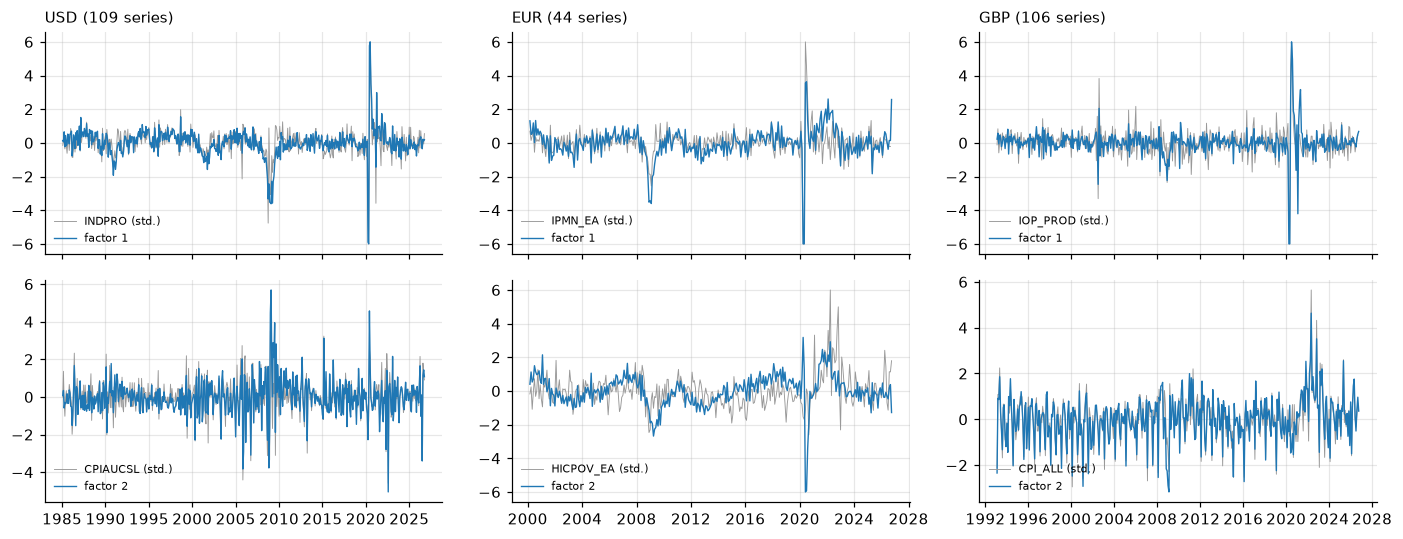

In [2]:
import yaml
from yck.model.macro_factors import RealTimeFactors, transform
spec = yaml.safe_load(CONFIG.read_text())["macro_panels"]
fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex="col")
corr = {}
for j, c in enumerate(CCYS):
    rt = RealTimeFactors.load(c, DATA, CONFIG, 2, start=BACKTEST_DEFAULTS[c][0])
    origin = y[c].index[-1]
    f = rt.at(origin)
    raw, tc = rt.panel_at(origin)
    anc = spec[c]["anchors"]
    x = transform(raw[anc], tc).loc[f.index]
    for i in range(2):
        ax = axes[i, j]
        z = (x[anc[i]] - x[anc[i]].mean()) / x[anc[i]].std()
        ax.plot(z.clip(-6, 6), lw=0.6, color="0.6", label=f"{anc[i]} (std.)")
        ax.plot(f[f"factor{i + 1}"].clip(-6, 6), lw=0.9, label=f"factor {i + 1}")
        ax.legend(fontsize=7, frameon=False, loc="lower left")
        corr[(c, f"factor {i + 1}")] = round(float(f[f"factor{i + 1}"].corr(x[anc[i]])), 2)
    axes[0, j].set_title(f"{c} ({raw.shape[1] - len(spec[c]['exclude'])} series)", loc="left", fontsize=10)
fig.tight_layout()
pd.Series(corr, name="correlation with anchor").unstack()

## 2. Do the factors add information?

- **Against yields only:** Clark–West, nested; one-sided stars in favour
  of the factor model. Cells are RMSE ratios (< 1 means the factors help).
- **Policy rate + 2 factors against the policy-rate model:** DM,
  two-sided.

In [3]:
def after(c, h):
    return y[c].loc[pd.Timestamp(FIRST_ORIGIN[c]) + pd.offsets.MonthEnd(h):]

def vs(c, bench, h, names, field="cell"):
    t = dm_table({n: fc[c][n][h] for n in [bench] + names}, bench, after(c, h), h, SHOW[c])
    return t.xs(field, axis=1, level=1).T

from yck.eval.stats import cw_table
for c in CCYS:
    rows = {}
    for h in H:
        for p in FAC:
            t = cw_table({YIELDS_OF[p]: fc[c][YIELDS_OF[p]][h], p: fc[c][p][h]}, YIELDS_OF[p], after(c, h), h, SHOW[c])
            rows[(f"h = {h}", p + " ÷ yields (CW)")] = t[(p, "cell")]
        for e in ("", " + AR(1)"):
            p, b = "policy rate + 2 factors" + e, "policy rate" + e
            rows[(f"h = {h}", p + " ÷ policy rate (DM)")] = vs(c, b, h, [p]).loc[p]
    display(pd.DataFrame(rows).T.style.set_caption(f"{c}").set_table_styles(CAP))

## 3. Against forwards and the random walk

In [4]:
SHOWN = ["yields", "policy rate", "full macro"] + [p for p in FAC if "AR(1)" not in p] + ["combination A, inverse MSE"]
for c in CCYS:
    t = pd.concat({**{f"÷ forwards, h = {h}": vs(c, "forwards", h, SHOWN) for h in H},
                   **{f"÷ RW, h = {h}": vs(c, "random walk", h, SHOWN, "ratio").astype(float).round(2) for h in H}},
                  axis=1)
    display(t.style.set_caption(f"{c}").set_table_styles(CAP))

## 4. Model confidence set over everything

The 90% MCS over every model in notebooks 02–10 (pooled squared-error
loss).

In [5]:
SHORT = "3m / 6m (GBP)"
mcs = {(c, h): mcs_table({n: f[h] for n, f in fc[c].items()}, after(c, h), h, SHOW[c], n_boot=2000)
               .rename(columns={SHOW[c][0]: SHORT})
       for c in CCYS for h in H}
summary = {(c, f"h = {h}"): {col: f"{int((t[col] >= 0.10).sum())} / {int(t[col].notna().sum())}" for col in t.columns}
           for (c, h), t in mcs.items()}
display(pd.DataFrame(summary).T.style.set_caption("Models in the 90% MCS / models compared").set_table_styles(CAP))
KEY = ["yields", "policy rate", "full macro"] + FAC + ["combination A, inverse MSE", "random walk", "forwards"]
pd.DataFrame({(c, f"h = {h}"): mcs[(c, h)].loc[KEY, "all"] for c in CCYS for h in H}).round(2)

USD                EUR                GBP  \
                                h = 1 h = 6 h = 12 h = 1 h = 6 h = 12 h = 1   
model                                                                         
yields                           0.00  0.96   0.99  0.00  0.43   0.56  0.00   
policy rate                      0.00  0.99   1.00  0.00  0.42   0.26  0.00   
full macro                       0.00  0.52   0.50  0.00  0.30   0.10  0.00   
1 factor                         0.00  0.98   1.00  0.00  0.55   0.56  0.00   
1 factor + AR(1)                 0.79  0.99   1.00  0.21  0.48   0.53  0.86   
2 factors                        0.00  0.95   1.00  0.00  0.27   0.42  0.00   
2 factors + AR(1)                0.77  0.96   1.00  0.04  0.25   0.42  0.70   
policy rate + 2 factors          0.00  0.99   1.00  0.00  0.35   0.22  0.00   
policy rate + 2 factors + AR(1)  0.88  0.99   1.00  0.03  0.30   0.21  0.56   
combination A, inverse MSE       1.00  0.99   1.00  0.87  0.96   0.86  0.86   
random walk                      0.71  0.99   1.00  0.87  0.96   0.95  0.87   
forwards                         1.00  0.99   1.00  1.00  1.00   1.00   NaN   

                                              
                                h = 6 h = 12  
model                                         
yields                           0.77   0.89  
policy rate                      0.77   0.80  
full macro                       0.38   0.17  
1 factor                         0.77   0.89  
1 factor + AR(1)                 0.77   0.88  
2 factors                        0.48   0.66  
2 factors + AR(1)                0.48   0.66  
policy rate + 2 factors          0.48   0.71  
policy rate + 2 factors + AR(1)  0.54   0.71  
combination A, inverse MSE       0.97   0.99  
random walk                      1.00   0.99  
forwards                         0.93   0.89

## 5. Takeaways

1. **The factors mean what they should.** At the last origin factor 1
   correlates 0.80–0.86 with industrial production in all three panels.
   Factor 2 correlates 0.88–0.94 with consumer prices in USD and GBP, but
   only 0.32 in EUR, where the second component is not price-led.
2. **USD: no information beyond the policy rate, even with real-time
   vintages.**
   - One or two factors against yields only: 0.99–1.02 at every horizon
     and maturity.
   - Policy rate + 2 factors against the policy-rate model: 0.99–1.01, not
     significant.
   - The significant Clark–West gains of "policy rate + 2 factors" over
     yields only (h = 6–12, 1–4%) are the policy rate's, already found in
     notebook 03.
3. **EUR and GBP: one factor is neutral, two factors hurt.**
   - **One factor:** small one-month gains in EUR (1–4%, Clark–West 1%);
     0.98–1.04 elsewhere.
   - **Two factors:** 5–16% worse in GBP and up to 17% worse at the EUR
     short end at h = 12.
   - **Adding two factors to the policy-rate model** makes it worse: GBP
     2–16%, significant at h = 1 and 6; EUR up to 9% (3m at h = 1, 1%).
4. **Confidence set.** No separation at h = 6–12: it keeps 56–70 of 58–70
   models. The 2-factor models have lower p-values in EUR and GBP
   (0.21–0.71) but stay in the set.
5. **Reading.** This fits the README's warning (§7.6): the large gains from
   macro factors in Moench (2008) and Coroneo, Giannone & Modugno (2016)
   come from pre-2008 US samples. Since 2008, and especially at the lower
   bound, yields have been driven by policy and its expected path. The
   policy rate (USD) and the forward curve already carry that, and broad
   activity and price factors do not.
6. **Not adopted.** Panel factors do not enter the step 8 models. The data
   pipeline (FRED-MD vintages, EA-MD-QD, UK-MD) stays, for the write-up and
   for anyone extending the project.